In [40]:
!pip install astroquery

Looking in indexes: https://test.pypi.org/simple/


In [28]:
!pip uninstall https://test.pypi.org/simple/ astronomy-research-team16 --yes

Found existing installation: astronomy-research-team16 0.0.4
Uninstalling astronomy-research-team16-0.0.4:
  Successfully uninstalled astronomy-research-team16-0.0.4


In [29]:
!pip install -i https://test.pypi.org/simple/ astronomy-research-team16

Looking in indexes: https://test.pypi.org/simple/
  Using cached https://test-files.pythonhosted.org/packages/8a/d6/5906ed8f660529aa234f73042da58303545086d47c7e95970852aa2d87a5/astronomy_research_team16-0.0.4-py3-none-any.whl (11 kB)


In [30]:
import pandas as pd
from astronomy_research_team16.data_preprocessing import *
from astronomy_research_team16.metadata_extraction import *
from astronomy_research_team16.data_query import *
from astronomy_research_team16.wavelength_alignment import *
from astronomy_research_team16.data_augmentation import *
from astronomy_research_team16.spectral_feature_extraction import *
from astronomy_research_team16.visualization import *
from astronomy_research_team16.machine_learning import *

### Tutorial
This notebook is a tutorial for how to use the package for astronomy analysis

#### Load Data
The package provides a couple ways to load data as demonstrated below. You could:
1. input a SQL query that extracts the needed data from SDSS
2. input a fits file that's compatible with the SDSS database
3. input a query that pulls a list of fiberid, plateid, and mjd for needed spectrums

Method 1 offers your flexibility to construct your own data with SQL. Method 2 and 3 returns standard structured hdu tables. Particularly hdu 1, 2,3 since they contain the most relevant data

To learn more about the data. Read documentation here: https://data.sdss.org/datamodel/files/BOSS_SPECTRO_REDUX/RUN2D/spectra/PLATE4/spec.html

In [31]:
### load data with sql queries.
### you can construct your own query
adql_query = """
SELECT TOP 10 u as ultraviolet, g as green, r as red, i as near_infrared,
    p.z as infrared, objID as identifier, rowc as row_center_position,
    colc as column_center_position, s.z as redshift, s.class as class,
    p.sky_u as ultraviolet_flux, p.sky_g as green_flux, p.sky_r as red_flux,
    p.sky_i as near_infrared_flux, p.sky_z as infrared_flux
    FROM PhotoObj as p JOIN SpecObj as s on p.specObjID=s.specObjID
"""
data1=load_data_sql(adql_query=adql_query)
data1.head(5)

/usr/local/lib/python3.10/dist-packages/astroquery/sdss/core.py:874: VisibleDeprecationWarning: Reading unicode strings without specifying the encoding argument is deprecated. Set the encoding, use None for the system default.
  arr = np.atleast_1d(np.genfromtxt(io.BytesIO(response.content),


,ultraviolet,green,red,near_infrared,infrared,identifier,row_center_position,column_center_position,redshift,class,ultraviolet_flux,green_flux,red_flux,near_infrared_flux,infrared_flux
0,25.82660,23.06506,20.75891,19.74327,19.41578,1237680313910362326,1407.3930,1476.254,0.475454,b'GALAXY',2.258010,2.023504,7.331810,14.33041,44.50262
1,26.91186,20.36330,18.51741,17.91003,17.46696,1237680313910428022,460.4040,1376.382,0.348952,b'GALAXY',2.251511,2.007847,7.254937,14.05999,44.46958
2,23.64305,21.77221,20.03065,18.99487,18.53317,1237680313910428411,96.4855,1180.567,0.474355,b'GALAXY',2.233537,2.010497,7.274924,14.09908,44.44875
3,26.51201,22.51237,20.91223,19.84286,19.33347,1237680313910428432,207.9833,1148.107,0.576634,b'GALAXY',2.233958,2.011827,7.273147,14.08087,44.47076
4,20.12778,19.37125,18.95807,18.85274,18.60966,1237680313910493401,245.1909,1402.805,3.393394,b'QSO',2.243108,2.004951,7.195599,14.00218,44.08349


In [32]:
### load data with fits file if you already have your data in such format that's compatible with SDSS
data2 = load_data_file(file="spectrum.fits")

# the hdu tables will be stored in the dictionary
print("hdu 1")
print(data2['hdu_1'].head(3))
print("hdu 2")
print(data2['hdu_2'].head(3))
print("hdu 3")
print(data2['hdu_3'].head(3))

hdu 1
        flux  loglam      ivar  and_mask  or_mask     wdisp       sky  \
0  57.726517  3.5543  0.028316         0        0  1.168593  5.010036   
1  59.701256  3.5544  0.029463         0        0  1.168603  4.994220   
2  57.746086  3.5545  0.032101         0        0  1.168612  4.980797   

       model CLASS            SPECOBJID         Z  
0  56.323662  STAR  4565688039389812736 -0.000334  
1  54.646454  STAR  4565688039389812736 -0.000334  
2  52.852806  STAR  4565688039389812736 -0.000334  
hdu 2
          Z        RA       DEC CLASS            SPECOBJID  \
0 -0.000334  235.8026  2.714873  STAR  4565688039389812736   

                 OBJID  
0  1237654879672402053  
hdu 3
   PLATE    MJD  FIBERID   LINENAME  LINEWAVE  LINEZ  LINEZ_ERR  LINESIGMA  \
0   4055  55359      596   Ly_alpha   1215.67    0.0       -1.0        0.0   
1   4055  55359      596   N_V 1240   1240.81    0.0       -1.0        0.0   
2   4055  55359      596  C_IV 1549   1549.48    0.0       -1.0        0

In [6]:
### load data with a query that returns a list of plateid, fiberid, and mjd of the spectrum to retreive
adql_query = """
SELECT top 10 plate,mjd,fiberid
FROM dbo.SpecObj
"""
data3 = load_data_ids(adql_query)

# the hdu tables will be stored in the dictionary
print("hdu 1")
print(data3['hdu_1'].head(3))
print("hdu 2")
print(data3['hdu_2'].head(3))
print("hdu 3")
print(data3['hdu_3'].head(3))

/usr/local/lib/python3.10/dist-packages/astroquery/sdss/core.py:874: VisibleDeprecationWarning: Reading unicode strings without specifying the encoding argument is deprecated. Set the encoding, use None for the system default.
  arr = np.atleast_1d(np.genfromtxt(io.BytesIO(response.content),
/usr/local/lib/python3.10/dist-packages/astroquery/sdss/core.py:874: VisibleDeprecationWarning: Reading unicode strings without specifying the encoding argument is deprecated. Set the encoding, use None for the system default.
  arr = np.atleast_1d(np.genfromtxt(io.BytesIO(response.content),
/usr/local/lib/python3.10/dist-packages/astroquery/sdss/core.py:874: VisibleDeprecationWarning: Reading unicode strings without specifying the encoding argument is deprecated. Set the encoding, use None for the system default.
  arr = np.atleast_1d(np.genfromtxt(io.BytesIO(response.content),
/usr/local/lib/python3.10/dist-packages/astroquery/sdss/core.py:874: VisibleDeprecationWarning: Reading unicode strings w

hdu 1
       flux  loglam      ivar  and_mask  or_mask     wdisp       sky  \
0  1.114872  3.5572  0.062298         0        0  1.225221  0.719133   
1  0.570260  3.5573  0.056394         0        0  1.224991  0.772733   
2 -1.318258  3.5574  0.057568         0        0  1.224760  0.819455   

      model   CLASS     SPECOBJID         Z  
0  0.013242  GALAXY  7.048316e+18  0.475454  
1  0.010971  GALAXY  7.048316e+18  0.475454  
2  0.009363  GALAXY  7.048316e+18  0.475454  
hdu 2
          Z         RA        DEC   CLASS     SPECOBJID                OBJID
0  0.475454  15.988669  31.121304  GALAXY  7.048316e+18  1237680313910362326
0  0.285623  15.985478  31.107748  GALAXY  7.423108e+18  1237680313910362888
0 -0.000122  16.161879  31.118444    STAR  7.423103e+18  1237680313910427963
hdu 3
   PLATE    MJD  FIBERID   LINENAME  LINEWAVE  LINEZ  LINEZ_ERR  LINESIGMA  \
0   6260  56568      665   Ly_alpha   1215.67    0.0       -1.0        0.0   
1   6260  56568      665   N_V 1240   1240.81

In the rest of the tutorial, we will show how to use data returned from fits files/plateid,fiberid, mjd as an example because they are most standard and commonly used

#### Data preprocessing
This module contains functions for you to clean and process your data for further analysis

##### Normalize data
For example, if I want to normalize wavelenght data from hdu_1

In [7]:
normalized_data = normalize(data3['hdu_1'])
normalized_data.head(5)

,flux,loglam,ivar,and_mask,or_mask,wdisp,sky,model,CLASS,SPECOBJID,Z
0,-0.528763,-1.708062,-1.237212,-0.211748,-0.64116,2.291890,-0.400541,-0.641849,GALAXY,-1.230494,-0.175694
1,-0.585655,-1.707309,-1.237962,-0.211748,-0.64116,2.290118,-0.396032,-0.642088,GALAXY,-1.230494,-0.175694
2,-0.782937,-1.706558,-1.237813,-0.211748,-0.64116,2.288330,-0.392101,-0.642258,GALAXY,-1.230494,-0.175694
3,-0.321991,-1.705807,-1.237589,-0.211748,-0.64116,2.286556,-0.386270,-0.642325,GALAXY,-1.230494,-0.175694
4,-1.032598,-1.705055,-1.237589,-0.211748,-0.64116,2.284781,-0.370770,-0.642290,GALAXY,-1.230494,-0.175694


In [8]:
normalized_data.shape

(46076, 11)

##### Remove outliers
Now if you want to further remove outliers, you can clal the remove_outliers function on the columns you want to perform this action on and specified a threshold. e.g. 0.1 means top and bottom 5% outliers will be removed

In [9]:
data_no_outliers = remove_outliers(normalized_data, threshold=0.1,to_remove_columns=["flux"])
data_no_outliers.head(5)

,flux,loglam,ivar,and_mask,or_mask,wdisp,sky,model,CLASS,SPECOBJID,Z
0,-0.528763,-1.708062,-1.237212,-0.211748,-0.64116,2.291890,-0.400541,-0.641849,GALAXY,-1.230494,-0.175694
1,-0.585655,-1.707309,-1.237962,-0.211748,-0.64116,2.290118,-0.396032,-0.642088,GALAXY,-1.230494,-0.175694
2,-0.321991,-1.705807,-1.237589,-0.211748,-0.64116,2.286556,-0.386270,-0.642325,GALAXY,-1.230494,-0.175694
3,-0.044089,-1.703551,-1.238412,-0.211748,-0.64116,2.281245,-0.339188,-0.642029,GALAXY,-1.230494,-0.175694
4,-0.591395,-1.702800,-1.237408,-0.211748,-0.64116,2.279480,-0.321329,-0.641885,GALAXY,-1.230494,-0.175694


you can see that 4000 data is removed

In [10]:
data_no_outliers.shape

(41468, 11)

##### Interpolation
You can also perform interpolation on flux and wavelength if there is missing data

In [11]:
interpolated_data = interpolate(data_no_outliers,flux_column='flux', wavelength_column='loglam')
interpolated_data.head(5)

,flux,loglam,ivar,and_mask,or_mask,wdisp,sky,model,CLASS,SPECOBJID,Z
0,-0.528763,-1.708062,-1.237212,-0.211748,-0.64116,2.291890,-0.400541,-0.641849,GALAXY,-1.230494,-0.175694
1,-0.585655,-1.707309,-1.237962,-0.211748,-0.64116,2.290118,-0.396032,-0.642088,GALAXY,-1.230494,-0.175694
2,-0.321991,-1.705807,-1.237589,-0.211748,-0.64116,2.286556,-0.386270,-0.642325,GALAXY,-1.230494,-0.175694
3,-0.044089,-1.703551,-1.238412,-0.211748,-0.64116,2.281245,-0.339188,-0.642029,GALAXY,-1.230494,-0.175694
4,-0.591395,-1.702800,-1.237408,-0.211748,-0.64116,2.279480,-0.321329,-0.641885,GALAXY,-1.230494,-0.175694


##### Redshift correction
You may also want to correct your wavelength by the redshift in the data

In [12]:
corrected_data = correct_redshift(data3['hdu_1'],redshift_column='Z',wavelenght_column='loglam')
corrected_data.head(5)

,flux,loglam,ivar,and_mask,or_mask,wdisp,sky,model,CLASS,SPECOBJID,Z
0,-0.528763,-1.407966,-1.237212,-0.211748,-0.64116,2.291890,-0.400541,-0.641849,GALAXY,-1.230494,-0.175694
1,-0.585655,-1.407345,-1.237962,-0.211748,-0.64116,2.290118,-0.396032,-0.642088,GALAXY,-1.230494,-0.175694
2,-0.782937,-1.406726,-1.237813,-0.211748,-0.64116,2.288330,-0.392101,-0.642258,GALAXY,-1.230494,-0.175694
3,-0.321991,-1.406107,-1.237589,-0.211748,-0.64116,2.286556,-0.386270,-0.642325,GALAXY,-1.230494,-0.175694
4,-1.032598,-1.405487,-1.237589,-0.211748,-0.64116,2.284781,-0.370770,-0.642290,GALAXY,-1.230494,-0.175694


#### Metadata Extraction
The package also offers a nice way to extract pertinent metadata for each spectrum in the data. <br> Since the metadata lies in multiple different places within the data query, we will used a merged dataframe to illustrate the utility of this function.

In [13]:
# Creating the merged data frame with the data3 object used above
metadata_1 = data3['hdu_2']
metadata_2 = data3['hdu_3']
metadata_2 = pd.merge(metadata_1, metadata_2, left_index=True, right_index=True)
metadata_1 = data3['hdu_1']
merged_meta = pd.merge(metadata_1, metadata_2, left_index=True, right_index=True)
print(merged_meta.columns)

Index(['flux', 'loglam', 'ivar', 'and_mask', 'or_mask', 'wdisp', 'sky',
       'model', 'CLASS', 'SPECOBJID', 'Z', 'Z_x', 'RA', 'DEC', 'CLASS_x',
       'SPECOBJID_x', 'OBJID', 'PLATE', 'MJD', 'FIBERID', 'LINENAME',
       'LINEWAVE', 'LINEZ', 'LINEZ_ERR', 'LINESIGMA', 'LINESIGMA_ERR',
       'LINEAREA', 'LINEAREA_ERR', 'LINEEW', 'LINEEW_ERR', 'LINECONTLEVEL',
       'LINECONTLEVEL_ERR', 'LINENPIXLEFT', 'LINENPIXRIGHT', 'LINEDOF',
       'LINECHI2', 'CLASS_y', 'SPECOBJID_y', 'Z_y'],
      dtype='object')


In [14]:
metadata = extract_metadata(merged_meta, identifiers=True, equivalent_width=True, coordinates=True, redshifts=True, other_fields=None)
metadata.head(5)

,specObjID,equivalent_width,coord.red_ascension,coord.declination,redshift
0,-1.230494,0.0,15.988669,31.121304,-0.175694
0,-1.230494,0.0,15.988669,31.121304,-0.175694
0,-1.230494,0.0,15.988669,31.121304,-0.175694
0,-1.230494,0.0,15.988669,31.121304,-0.175694
0,-1.230494,0.0,15.988669,31.121304,-0.175694


#### Wavelength Alignment
The package also offers a function to align the wavelength for all spectra within a predefined range.

In [15]:
align_wavelength(corrected_data, wavelength_range=(-0.5, 2), interpolation=False)

,flux,loglam,ivar,and_mask,or_mask,wdisp,sky,model,CLASS,SPECOBJID,Z
1466,-0.637186,-0.499534,0.537983,-0.211748,-0.64116,0.227367,-0.277353,-0.593267,GALAXY,-1.230494,-0.175694
1467,-0.596738,-0.498914,0.380829,-0.211748,-0.64116,0.226432,-0.268831,-0.592905,GALAXY,-1.230494,-0.175694
1468,-0.580986,-0.498295,0.432496,-0.211748,-0.64116,0.225505,-0.275138,-0.592578,GALAXY,-1.230494,-0.175694
1469,-0.566270,-0.497676,0.259693,-0.211748,-0.64116,0.224570,-0.273417,-0.592214,GALAXY,-1.230494,-0.175694
1470,-0.572453,-0.497055,0.367221,-0.211748,-0.64116,0.223637,-0.274435,-0.592149,GALAXY,-1.230494,-0.175694
...,...,...,...,...,...,...,...,...,...,...,...
4577,0.949172,0.880915,-1.237531,-0.211748,-0.64116,-0.808784,2.153059,0.490917,GALAXY,-1.230436,-0.491585
4578,0.776918,0.881296,-1.238366,-0.211748,-0.64116,-0.804511,2.364776,0.492766,GALAXY,-1.230436,-0.491585
4579,0.386156,0.881679,-1.232855,-0.211748,-0.64116,-0.799986,0.496417,0.496088,GALAXY,-1.230436,-0.491585
4580,0.678773,0.882061,-1.233217,-0.211748,-0.64116,-0.795574,0.344730,0.500627,GALAXY,-1.230436,-0.491585


#### Plotting functionalities
The package also offers a plot function to plot flux vs wavelength with modeled continum from the table hdu_1

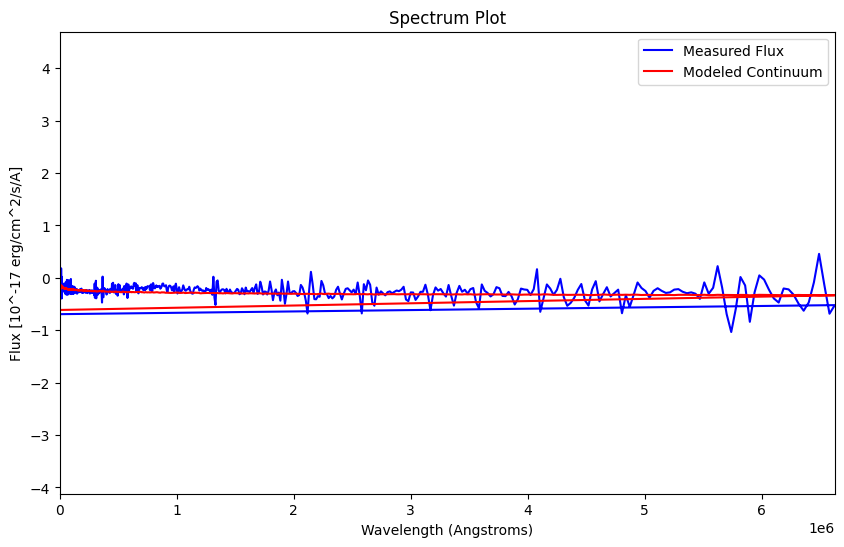

In [16]:
plot_spectrum(data3['hdu_1'])

#### Data Augmentation

This package is able to compute derivatives as well as fractional derivatives of flux respective to wavelength and append them to each preprocessed spectra.

In [17]:
# augmented dataframe with standard derivative
augmented_data_deriv = augment_data(corrected_data, ['standard_derivative'])
augmented_data_deriv.head(5)

,flux,loglam,ivar,and_mask,or_mask,wdisp,sky,model,CLASS,SPECOBJID,Z,flux_std_deriv
0,-0.528763,-1.407966,-1.237212,-0.211748,-0.64116,2.291890,-0.400541,-0.641849,GALAXY,-1.230494,-0.175694,-91.689911
1,-0.585655,-1.407345,-1.237962,-0.211748,-0.64116,2.290118,-0.396032,-0.642088,GALAXY,-1.230494,-0.175694,-205.055099
2,-0.782937,-1.406726,-1.237813,-0.211748,-0.64116,2.288330,-0.392101,-0.642258,GALAXY,-1.230494,-0.175694,212.957520
3,-0.321991,-1.406107,-1.237589,-0.211748,-0.64116,2.286556,-0.386270,-0.642325,GALAXY,-1.230494,-0.175694,-201.414642
4,-1.032598,-1.405487,-1.237589,-0.211748,-0.64116,2.284781,-0.370770,-0.642290,GALAXY,-1.230494,-0.175694,-261.387939


In [18]:
# augmented dataframe with fractional derivative
augmented_data_frac = augment_data(corrected_data, ['fractional_derivative'], 0.5)
augmented_data_frac.head(5)

,flux,loglam,ivar,and_mask,or_mask,wdisp,sky,model,CLASS,SPECOBJID,Z,flux_frac_deriv
0,-0.528763,-1.407966,-1.237212,-0.211748,-0.64116,2.291890,-0.400541,-0.641849,GALAXY,-1.230494,-0.175694,-269482.345796
1,-0.585655,-1.407345,-1.237962,-0.211748,-0.64116,2.290118,-0.396032,-0.642088,GALAXY,-1.230494,-0.175694,-298821.705384
2,-0.782937,-1.406726,-1.237813,-0.211748,-0.64116,2.288330,-0.392101,-0.642258,GALAXY,-1.230494,-0.175694,-399943.145030
3,-0.321991,-1.406107,-1.237589,-0.211748,-0.64116,2.286556,-0.386270,-0.642325,GALAXY,-1.230494,-0.175694,-164290.983980
4,-1.032598,-1.405487,-1.237589,-0.211748,-0.64116,2.284781,-0.370770,-0.642290,GALAXY,-1.230494,-0.175694,-526867.391167


In [19]:
# augmented dataframe with both methods
augmented_data = augment_data(corrected_data, ['standard_derivative','fractional_derivative'], 0.5)
augmented_data.head(5)

,flux,loglam,ivar,and_mask,or_mask,wdisp,sky,model,CLASS,SPECOBJID,Z,flux_std_deriv,flux_frac_deriv
0,-0.528763,-1.407966,-1.237212,-0.211748,-0.64116,2.291890,-0.400541,-0.641849,GALAXY,-1.230494,-0.175694,-91.689911,-269482.345796
1,-0.585655,-1.407345,-1.237962,-0.211748,-0.64116,2.290118,-0.396032,-0.642088,GALAXY,-1.230494,-0.175694,-205.055099,-298821.705384
2,-0.782937,-1.406726,-1.237813,-0.211748,-0.64116,2.288330,-0.392101,-0.642258,GALAXY,-1.230494,-0.175694,212.957520,-399943.145030
3,-0.321991,-1.406107,-1.237589,-0.211748,-0.64116,2.286556,-0.386270,-0.642325,GALAXY,-1.230494,-0.175694,-201.414642,-164290.983980
4,-1.032598,-1.405487,-1.237589,-0.211748,-0.64116,2.284781,-0.370770,-0.642290,GALAXY,-1.230494,-0.175694,-261.387939,-526867.391167


#### Machine Learning
In addition to processing and understanding the data, the package also offers machine learning capabilities. Particularly, the below functions will train a classifier - Random Forest to predict class (Star, Galaxy, ) with spectrum data

There is not need to preprocess your data again for this test. You could just run prepare_data and it will return cleanned, normalized train and test data. You can run fit_model to train a model. The function will display a confusion matrix for the trained model

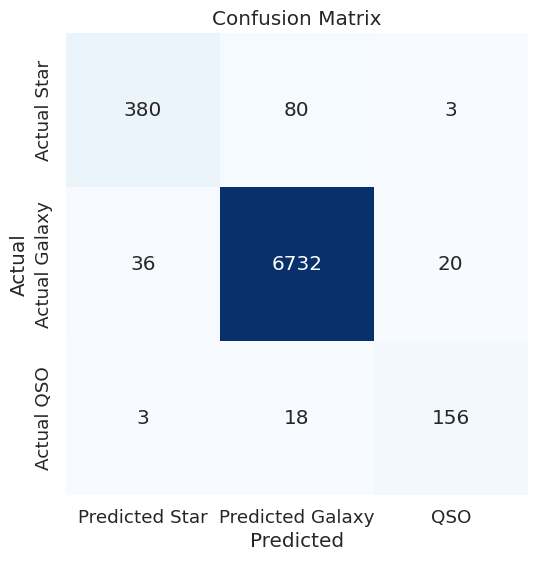

In [20]:
X_train, X_val, y_train, y_val, X_test =prepare_data(data3)
model=fit_model(X_train,y_train,X_val,y_val)

You can also get prediction on some test data split from the original dataset using the trained model

In [21]:
prediction=predict_class(model,X_test)
prediction_prob=predict_proba(model,X_test)
prediction

0       GALAXY
1       GALAXY
2       GALAXY
3       GALAXY
4       GALAXY
         ...  
7423    GALAXY
7424      STAR
7425    GALAXY
7426    GALAXY
7427    GALAXY
Length: 7428, dtype: object

#### Spectral Feature Extraction   
We can derive both the emission and absoption spectra from the flux and wavelength data as two seperate arrays seen below:

In [24]:
emission, absorption, error = extract_spectral_features(merged_meta)
print("Emission Wavelengths:", emission)
print("Absorption Wavelengths:", absorption)

Emission Wavelengths: []
Absorption Wavelengths: [0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298 0.13539298
 0.13539298 0